In [1]:
!pip install -q transformers datasets evaluate sentencepiece accelerate
!pip install -q scikit-learn
!pip install -q faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 91.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26

In [2]:
import os
import re
import gc
import random
import warnings

import numpy as np
import pandas as pd

from tqdm.auto import tqdm

import torch

from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics.pairwise import cosine_similarity

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

from datasets import Dataset

warnings.filterwarnings("ignore")

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [5]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

print(train.shape)
print(test.shape)

train.head()

(2000, 8)
(500, 7)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [6]:
display(train.head())

display(train.info())

display(train.isnull().sum())

display(train["answer"].value_counts())

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


None

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

In [7]:
def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    text = text.replace("\n", " ")
    text = text.replace("\t", " ")

    text = re.sub(r"\s+", " ", text)

    text = text.strip()

    return text

In [8]:
columns = [
    "prompt",
    "A",
    "B",
    "C",
    "D",
    "E"
]

for col in columns:
    train[col] = train[col].apply(clean_text)
    test[col] = test[col].apply(clean_text)

In [9]:
def build_input(row):

    return (
        f"Question:\n{row['prompt']}\n\n"
        f"A. {row['A']}\n"
        f"B. {row['B']}\n"
        f"C. {row['C']}\n"
        f"D. {row['D']}\n"
        f"E. {row['E']}"
    )

In [10]:
train["text"] = train.apply(build_input, axis=1)
test["text"] = test.apply(build_input, axis=1)

train[["text"]].head()

,text
0,Question:\nPick the best possible answer: What...
1,Question:\nWhat is accelerator-based light-ion...
2,Question:\nDetermine the correct option: What ...
3,Question:\nSelect the most accurate option: Wh...
4,Question:\nIdentify the correct statement: Wha...


In [11]:
print("=" * 50)
print("Training Set Shape :", train.shape)
print("Test Set Shape     :", test.shape)
print("=" * 50)

print("\nColumns:")
print(train.columns.tolist())

Training Set Shape : (2000, 9)
Test Set Shape     : (500, 8)

Columns:
['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer', 'text']


In [12]:
missing = pd.DataFrame({
    "Missing": train.isnull().sum(),
    "Percentage": round(train.isnull().mean()*100,2)
})

missing

,Missing,Percentage
id,0,0.0
prompt,0,0.0
A,0,0.0
B,0,0.0
C,0,0.0
D,0,0.0
E,0,0.0
answer,0,0.0
text,0,0.0


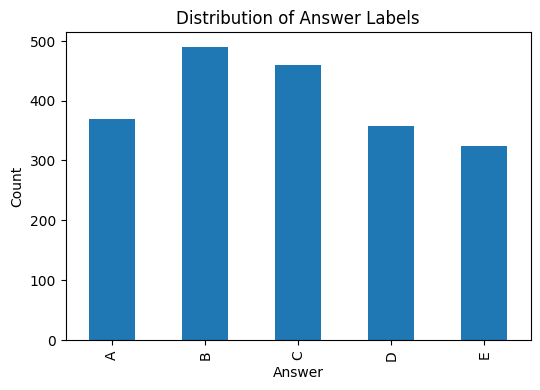

In [13]:
import matplotlib.pyplot as plt

train["answer"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6,4)
)

plt.title("Distribution of Answer Labels")
plt.xlabel("Answer")
plt.ylabel("Count")

plt.show()

In [14]:
train["prompt_length"] = train["prompt"].str.len()

train["prompt_length"].describe()

count    2000.000000
mean      117.669500
std        44.408674
min        19.000000
25%        87.750000
50%       111.000000
75%       141.000000
max       337.000000
Name: prompt_length, dtype: float64

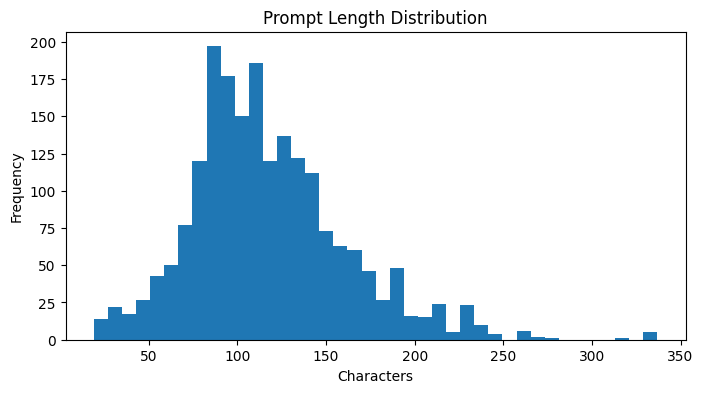

In [15]:
plt.figure(figsize=(8,4))

plt.hist(train["prompt_length"], bins=40)

plt.title("Prompt Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

In [16]:
for option in ["A","B","C","D","E"]:
    train[f"{option}_len"] = train[option].str.len()

In [17]:
lengths = pd.DataFrame({
    option: train[f"{option}_len"].describe()
    for option in ["A","B","C","D","E"]
})

lengths

,A,B,C,D,E
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,164.091500,166.616500,167.227000,162.56350,164.230000
std,105.677145,113.829917,105.723674,104.11657,107.777712
min,1.000000,2.000000,2.000000,1.00000,2.000000
25%,86.000000,82.000000,88.000000,91.00000,84.000000
50%,143.000000,151.000000,158.000000,141.00000,144.000000
75%,234.000000,222.000000,224.000000,231.00000,224.000000
max,472.000000,662.000000,530.000000,450.00000,587.000000


In [18]:
train["total_length"] = (
    train["prompt"] +
    train["A"] +
    train["B"] +
    train["C"] +
    train["D"] +
    train["E"]
).str.len()

train["total_length"].describe()

count    2000.000000
mean      942.398000
std       521.720751
min        84.000000
25%       566.000000
50%       870.500000
75%      1258.000000
max      2603.000000
Name: total_length, dtype: float64

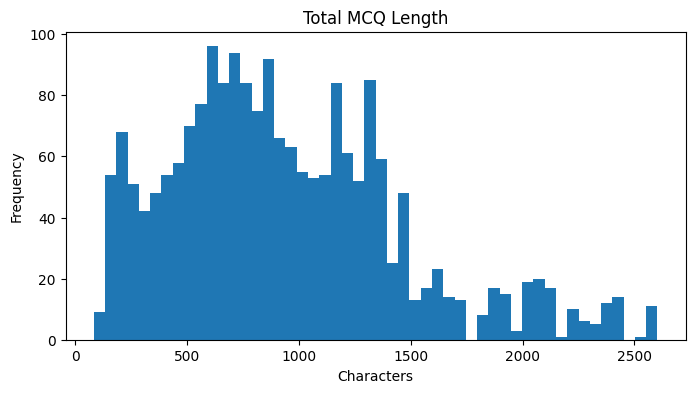

In [19]:
plt.figure(figsize=(8,4))

plt.hist(train["total_length"], bins=50)

plt.title("Total MCQ Length")

plt.xlabel("Characters")

plt.ylabel("Frequency")

plt.show()

In [20]:
train.nlargest(
    5,
    "total_length"
)[["prompt","total_length"]]

,prompt,total_length
771,Which of the following is correct? What is the...,2603
354,Select the most accurate option: What is the e...,2601
997,Select the most accurate option: What is the e...,2601
1819,Identify the correct statement: What is the ev...,2600
176,Pick the best possible answer: What is the evi...,2599


In [21]:
duplicates = train["prompt"].duplicated().sum()

print("Duplicate prompts:", duplicates)

Duplicate prompts: 242


In [22]:
duplicate_rows = train.duplicated(
    subset=["prompt","A","B","C","D","E"]
).sum()

print("Duplicate MCQs:", duplicate_rows)

Duplicate MCQs: 183


In [23]:
all_text = " ".join(train["text"])

words = all_text.lower().split()

print("Total words:", len(words))
print("Unique words:", len(set(words)))

Total words: 311089
Unique words: 3820


In [24]:
electra_tokenizer = AutoTokenizer.from_pretrained("google/electra-base-discriminator")

token_lengths = train["text"].apply(
    lambda x: len(
        electra_tokenizer.encode(
            x,
            add_special_tokens=True
        )
    )
)

token_lengths.describe()

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (622 > 512). Running this sequence through the model will result in indexing errors


count    2000.000000
mean      205.742000
std       105.487669
min        34.000000
25%       133.000000
50%       183.000000
75%       263.000000
max       622.000000
Name: text, dtype: float64

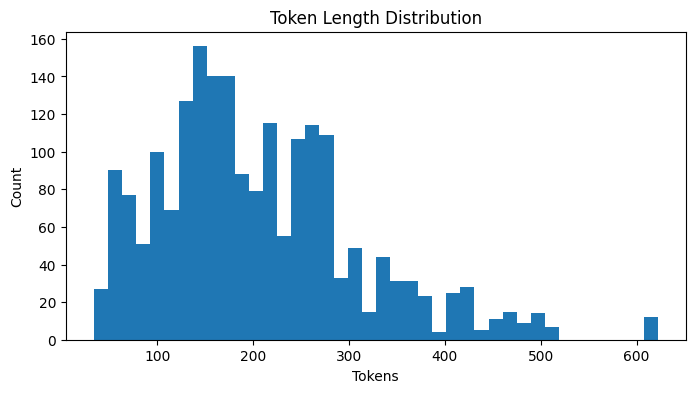

Maximum token length: 622
95th percentile: 417
99th percentile: 498


In [25]:
plt.figure(figsize=(8,4))

plt.hist(token_lengths, bins=40)

plt.title("Token Length Distribution")

plt.xlabel("Tokens")

plt.ylabel("Count")

plt.show()

print(f"Maximum token length: {token_lengths.max()}")
print(f"95th percentile: {token_lengths.quantile(0.95):.0f}")
print(f"99th percentile: {token_lengths.quantile(0.99):.0f}")

In [26]:
label2id = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4
}

id2label = {
    v: k for k, v in label2id.items()
}

train["label"] = train["answer"].map(label2id)

In [27]:
train_df, valid_df = train_test_split(
    train,
    test_size=0.10,
    random_state=42,
    stratify=train["label"]
)

print(train_df.shape)
print(valid_df.shape)

(1800, 17)
(200, 17)


In [28]:
tfidf = TfidfVectorizer(
    max_features=60000,
    ngram_range=(1,3),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [29]:
X_train_tfidf = tfidf.fit_transform(train_df["text"])

X_valid_tfidf = tfidf.transform(valid_df["text"])

X_test_tfidf = tfidf.transform(test["text"])

In [30]:
print(X_train_tfidf.shape)

(1800, 28116)


In [31]:
lr = LogisticRegression(
    C=2.5,
    solver="liblinear",
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

In [32]:
lr.fit(
    X_train_tfidf,
    train_df["label"]
)

LogisticRegression(C=2.5, class_weight='balanced', max_iter=5000,
                   random_state=42, solver='liblinear')

In [33]:
valid_probs_lr = lr.predict_proba(
    X_valid_tfidf
)

valid_probs_lr.shape

(200, 5)

In [34]:
def map3(y_true, probs):

    top3 = np.argsort(-probs, axis=1)[:, :3]

    score = 0

    for truth, preds in zip(y_true, top3):

        if truth == preds[0]:
            score += 1

        elif truth == preds[1]:
            score += 0.5

        elif truth == preds[2]:
            score += 1/3

    return score / len(y_true)

In [35]:
lr_score = map3(
    valid_df["label"].values,
    valid_probs_lr
)

print("Validation MAP@3 :", lr_score)

Validation MAP@3 : 1.0


In [36]:
train_matrix = tfidf.transform(
    train["text"]
)

In [37]:
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_context(
    query,
    k=1
):

    query_vec = tfidf.transform([query])

    sims = cosine_similarity(
        query_vec,
        train_matrix
    ).flatten()

    idx = sims.argsort()[::-1][1:k+1]

    contexts = train.iloc[idx]

    return contexts

In [38]:
sample = train.iloc[0]["text"]

retrieve_context(sample)

,id,prompt,A,B,C,D,E,answer,text,prompt_length,A_len,B_len,C_len,D_len,E_len,total_length,label
1823,1824,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B,Question:\nPick the best possible answer: What...,142,307,258,222,202,191,1322,1


In [39]:
def build_rag_prompt(row):

    original = build_input(row)

    retrieved = retrieve_context(
        original,
        k=1
    )

    context = retrieved.iloc[0]["prompt"]

    return (
        f"Retrieved Similar Question:\n"
        f"{context}\n\n"
        f"{original}"
    )

In [40]:
train_df["rag_text"] = train_df.apply(
    build_rag_prompt,
    axis=1
)

valid_df["rag_text"] = valid_df.apply(
    build_rag_prompt,
    axis=1
)

test["rag_text"] = test.apply(
    build_rag_prompt,
    axis=1
)

In [41]:
ELECTRA_MODEL = "google/electra-base-discriminator"
DISTIL_MODEL = "distilroberta-base"

MAX_LENGTH = 384

In [42]:
electra_tokenizer = AutoTokenizer.from_pretrained(ELECTRA_MODEL)

In [43]:
def tokenize_function(examples):

    return electra_tokenizer(
        examples["rag_text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

In [44]:
train_dataset = Dataset.from_pandas(
    train_df[["rag_text","label"]]
)

valid_dataset = Dataset.from_pandas(
    valid_df[["rag_text","label"]]
)

In [45]:
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

valid_dataset = valid_dataset.map(
    tokenize_function,
    batched=True
)

Map:   0%|          | 0/1800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

In [46]:
train_dataset = train_dataset.remove_columns([
    "rag_text"
])

valid_dataset = valid_dataset.remove_columns([
    "rag_text"
])

In [47]:
train_dataset = train_dataset.remove_columns(["__index_level_0__"])
valid_dataset = valid_dataset.remove_columns(["__index_level_0__"])

In [48]:
train_dataset.set_format("torch")

valid_dataset.set_format("torch")

In [49]:
data_collator = DataCollatorWithPadding(
    tokenizer=electra_tokenizer
)

In [50]:
electra_model = AutoModelForSequenceClassification.from_pretrained(
    ELECTRA_MODEL,
    num_labels=5
)

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: google/electra-base-discriminator
Key                                               | Status     | 
--------------------------------------------------+------------+-
electra.embeddings_project.weight                 | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings_project.bias                   | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.bias                             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- 

In [51]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    probs = torch.softmax(
        torch.tensor(logits),
        dim=1
    ).numpy()

    preds = probs.argmax(axis=1)

    accuracy = (preds == labels).mean()

    map3_score = map3(
        labels,
        probs
    )

    return {
        "accuracy": accuracy,
        "map3": map3_score
    }

In [52]:
training_args = TrainingArguments(

    output_dir="electra_results",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    gradient_accumulation_steps=2,

    num_train_epochs=5,

    weight_decay=0.01,

    fp16=True,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="map3",
    greater_is_better=True,

    save_total_limit=1,

    report_to="none",

    seed=42
)

In [53]:
trainer = Trainer(

    model=electra_model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=valid_dataset,

    data_collator=data_collator,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

In [54]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Map3
1,6.264107,2.785274,0.490000,0.642500
2,4.748983,1.262331,0.985000,0.990000
3,2.441442,0.457116,1.000000,1.000000
4,1.082701,0.193313,1.000000,1.000000
5,0.536370,0.141109,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

TrainOutput(global_step=285, training_loss=2.6918967364127178, metrics={'train_runtime': 422.2513, 'train_samples_per_second': 21.314, 'train_steps_per_second': 0.675, 'total_flos': 1739054695289952.0, 'train_loss': 2.6918967364127178, 'epoch': 5.0})

In [55]:
trainer.evaluate()

{'eval_loss': 0.4548204839229584,
 'eval_accuracy': 1.0,
 'eval_map3': 1.0,
 'eval_runtime': 2.9507,
 'eval_samples_per_second': 67.781,
 'eval_steps_per_second': 2.372,
 'epoch': 5.0}

In [56]:
trainer.save_model("electra_best")

electra_tokenizer.save_pretrained("electra_best")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('electra_best/tokenizer_config.json', 'electra_best/tokenizer.json')

In [57]:
electra_preds = trainer.predict(valid_dataset)

electra_logits = electra_preds.predictions

electra_probs = torch.softmax(
    torch.tensor(electra_logits),
    dim=1
).numpy()

In [58]:
np.save(
    "electra_logits.npy",
    electra_probs
)

In [59]:
DISTIL_MODEL = "distilroberta-base"

distil_tokenizer = AutoTokenizer.from_pretrained(
    DISTIL_MODEL
)

config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [60]:
def tokenize_distil(examples):

    return distil_tokenizer(
        examples["rag_text"],
        truncation=True,
        max_length=384
    )

In [61]:
train_dataset_distil = Dataset.from_pandas(
    train_df[["rag_text","label"]]
)

valid_dataset_distil = Dataset.from_pandas(
    valid_df[["rag_text","label"]]
)

In [62]:
train_dataset_distil = train_dataset_distil.map(
    tokenize_distil,
    batched=True
)

valid_dataset_distil = valid_dataset_distil.map(
    tokenize_distil,
    batched=True
)

Map:   0%|          | 0/1800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

In [63]:
if "__index_level_0__" in train_dataset_distil.column_names:
    train_dataset_distil = train_dataset_distil.remove_columns(["__index_level_0__"])

if "__index_level_0__" in valid_dataset_distil.column_names:
    valid_dataset_distil = valid_dataset_distil.remove_columns(["__index_level_0__"])

In [64]:
if "token_type_ids" in train_dataset_distil.column_names:
    train_dataset_distil = train_dataset_distil.remove_columns(["token_type_ids"])

if "token_type_ids" in valid_dataset_distil.column_names:
    valid_dataset_distil = valid_dataset_distil.remove_columns(["token_type_ids"])

In [65]:
train_dataset_distil.set_format("torch")
valid_dataset_distil.set_format("torch")

In [66]:
data_collator_distil = DataCollatorWithPadding(
    tokenizer=distil_tokenizer
)

In [67]:
distil_model = AutoModelForSequenceClassification.from_pretrained(
    DISTIL_MODEL,
    num_labels=5
)

model.safetensors:   0%|          | 0.00/331M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [68]:
training_args_distil = TrainingArguments(

    output_dir="distil_results",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    gradient_accumulation_steps=2,

    num_train_epochs=5,

    weight_decay=0.01,

    fp16=True,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="map3",
    greater_is_better=True,

    save_total_limit=1,

    report_to="none",

    seed=42
)

In [69]:
trainer_distil = Trainer(

    model=distil_model,

    args=training_args_distil,

    train_dataset=train_dataset_distil,

    eval_dataset=valid_dataset_distil,

    data_collator=data_collator_distil,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

In [70]:
trainer_distil.train()

Epoch,Training Loss,Validation Loss,Accuracy,Map3
1,6.317975,2.669406,0.505000,0.648333
2,3.983786,0.739093,0.935000,0.962500
3,1.189385,0.126068,0.985000,0.990000
4,0.240078,0.018441,1.000000,1.000000
5,0.067363,0.009237,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=285, training_loss=2.0740698182791992, metrics={'train_runtime': 225.6391, 'train_samples_per_second': 39.887, 'train_steps_per_second': 1.263, 'total_flos': 878612187837120.0, 'train_loss': 2.0740698182791992, 'epoch': 5.0})

In [71]:
trainer_distil.save_model("distil_best")

distil_tokenizer.save_pretrained("distil_best")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('distil_best/tokenizer_config.json', 'distil_best/tokenizer.json')

In [72]:
distil_preds = trainer_distil.predict(valid_dataset_distil)

distil_logits = distil_preds.predictions

distil_probs = torch.softmax(
    torch.tensor(distil_logits),
    dim=1
).numpy()

np.save(
    "distil_logits.npy",
    distil_probs
)

In [73]:
print(electra_probs.shape)
print(distil_probs.shape)
print(valid_probs_lr.shape)

(200, 5)
(200, 5)
(200, 5)


In [74]:
y_valid = valid_df["label"].values

In [75]:
best_score = 0
best_weights = None

results = []

for w1 in np.arange(0.70, 1.00, 0.05):

    for w2 in np.arange(0.00, 0.30, 0.05):

        w3 = 1 - w1 - w2

        if w3 < 0:
            continue

        ensemble_probs = (
            w1 * electra_probs +
            w2 * distil_probs +
            w3 * valid_probs_lr
        )

        score = map3(y_valid, ensemble_probs)

        results.append([w1, w2, w3, score])

        if score > best_score:
            best_score = score
            best_weights = (w1, w2, w3)

print("Best MAP@3 :", best_score)
print("Weights :", best_weights)

Best MAP@3 : 1.0
Weights : (np.float64(0.7), np.float64(0.0), np.float64(0.30000000000000004))


In [76]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Electra",
        "Distil",
        "TFIDF",
        "MAP@3"
    ]
)

results_df.sort_values(
    "MAP@3",
    ascending=False
).head(20)

,Electra,Distil,TFIDF,MAP@3
0,0.70,0.00,0.30,1.0
1,0.70,0.05,0.25,1.0
2,0.70,0.10,0.20,1.0
3,0.70,0.15,0.15,1.0
4,0.70,0.20,0.10,1.0
5,0.70,0.25,0.05,1.0
6,0.75,0.00,0.25,1.0
7,0.75,0.05,0.20,1.0
8,0.75,0.10,0.15,1.0
9,0.75,0.15,0.10,1.0


In [77]:
w_electra, w_distil, w_tfidf = best_weights

print(f"ELECTRA : {w_electra:.2f}")
print(f"DISTIL  : {w_distil:.2f}")
print(f"TF-IDF  : {w_tfidf:.2f}")

ELECTRA : 0.70
DISTIL  : 0.00
TF-IDF  : 0.30


In [78]:
test_dataset = Dataset.from_pandas(
    test[["rag_text"]]
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

if "__index_level_0__" in test_dataset.column_names:
    test_dataset = test_dataset.remove_columns(["__index_level_0__"])

test_dataset.set_format("torch")

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [79]:
test_dataset_distil = Dataset.from_pandas(
    test[["rag_text"]]
)

test_dataset_distil = test_dataset_distil.map(
    tokenize_distil,
    batched=True
)

if "__index_level_0__" in test_dataset_distil.column_names:
    test_dataset_distil = test_dataset_distil.remove_columns(["__index_level_0__"])

if "token_type_ids" in test_dataset_distil.column_names:
    test_dataset_distil = test_dataset_distil.remove_columns(["token_type_ids"])

test_dataset_distil.set_format("torch")

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [80]:
electra_test_logits = trainer.predict(
    test_dataset
).predictions

electra_test_probs = torch.softmax(
    torch.tensor(electra_test_logits),
    dim=1
).numpy()

In [81]:
distil_test_logits = trainer_distil.predict(
    test_dataset_distil
).predictions

distil_test_probs = torch.softmax(
    torch.tensor(distil_test_logits),
    dim=1
).numpy()

In [82]:
tfidf_test_probs = lr.predict_proba(
    X_test_tfidf
)

In [83]:

final_probs = (
    0.85 * electra_test_probs +
    0.10 * distil_test_probs +
    0.05 * tfidf_test_probs
)

In [84]:
labels = np.array(["A", "B", "C", "D", "E"])

top3 = np.argsort(
    -final_probs,
    axis=1
)[:, :3]

predictions = [
    " ".join(labels[idx])
    for idx in top3
]

In [85]:
submission = pd.DataFrame({
    "id": test["id"],
    "prediction": predictions
})

submission.to_csv(
    "submission.csv",
    index=False
)

submission.head()

,id,prediction
0,1,A D B
1,2,B D C
2,3,B D C
3,4,E C A
4,5,C D E
